In [ ]:

# %pip install -r requirements.txt

In [2]:
from pathlib import Path
import json, sys
ROOT=Path.cwd()
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
if not (ROOT/'stepguard_ml.py').is_file():
    raise FileNotFoundError('Extract the whole ZIP and open this notebook inside StepGuard_Sprint2.')
from demo_data import create_demo
from stepguard_ml import train_model,load_model
from stepguard_pipeline import analyse_video,convert_sprint1_evidence
from stepguard_rules import validate_procedure
WORK=ROOT/'work'/'notebook'
WORK.mkdir(parents=True,exist_ok=True)
print('Working directory:',WORK)

Working directory: /workspace/scratch/3794a45f5af2/output/StepGuard_Sprint2/work/notebook


In [3]:
data=create_demo(WORK/'demo_data')
procedure=validate_procedure(json.loads((data/'procedure.json').read_text()))
manifest=json.loads((data/'manifest.json').read_text())
print('SYNTHETIC fixture sessions:',len(manifest['sessions']))
print([(s['id'],s['split']) for s in manifest['sessions']])
print('Step IDs:',[s['id'] for s in procedure['steps']])

SYNTHETIC fixture sessions: 6
[('fixture_00', 'train'), ('fixture_01', 'train'), ('fixture_02', 'train'), ('fixture_03', 'train'), ('fixture_04', 'val'), ('fixture_05', 'val')]
Step IDs: ['S1', 'S2', 'S3']


In [4]:
model_path,training_report=train_model(data/'manifest.json',procedure,WORK/'demo_model',allow_synthetic=True)
print('SYNTHETIC TEST ONLY')
for name,metrics in training_report['metrics'].items():
    print(name,'validation macro-F1:',round(metrics['macro_f1'],4))
    print('Confusion matrix:',metrics['confusion_matrix'])
print('Checkpoint:',model_path)

SYNTHETIC TEST ONLY
frame_only validation macro-F1: 0.9791
Confusion matrix: [[16, 0, 0], [0, 15, 1], [0, 0, 16]]
temporal_average validation macro-F1: 0.8954
Confusion matrix: [[16, 0, 0], [3, 13, 0], [0, 2, 14]]
Checkpoint: /workspace/scratch/3794a45f5af2/output/StepGuard_Sprint2/work/notebook/demo_model/step_model.joblib


In [5]:
report=analyse_video(data/'demo_reordered.avi',model_path,data/'procedure.json',WORK/'demo_report',
                     component_path=data/'component_rule_fixture.json')
print('Data:',report['dataset_type'])
print('Frames:',report['processed_frames'])
print('Accepted step coverage:',round(report['coverage'],3))
print('States:',report['states'])
for alert in report['alerts']:
    print(alert['timestamp_seconds'],alert['type'],alert['details'])
    print('Guide:',alert['instruction'],alert['guide_ref'])

Data: SYNTHETIC MODEL DEMO
Frames: 32
Accepted step coverage: 0.906
States: {'S1': 'observed_checkpoint', 'S2': 'observed_checkpoint', 'S3': 'observed_checkpoint'}
5.0 sequence_prerequisite_unobserved ['S2']
Guide: Demo guide: inspect both wheel positions. Authored synthetic guide / step 3
13.5 visible_component_not_detected ['wheel']
Guide: Demo guide: inspect both wheel positions. Authored synthetic guide / step 3


  0.0s  S1       probable                   not_assessed
  0.5s  S1       observed_checkpoint        not_assessed
  1.0s  S1       observed_checkpoint        not_assessed
  1.5s  S1       observed_checkpoint        not_assessed
  2.0s  S1       observed_checkpoint        not_assessed
  2.5s  S1       observed_checkpoint        not_assessed
  3.0s  S1       observed_checkpoint        not_assessed
  3.5s  S1       observed_checkpoint        not_assessed
  4.0s  unknown  unknown                    not_assessed
  4.5s  S3       probable                   not_assessed
  5.0s  S3       prerequisite_unobserved    not_assessed
  5.5s  S3       prerequisite_unobserved    not_assessed
  6.0s  S3       prerequisite_unobserved    not_assessed
  6.5s  S3       prerequisite_unobserved    not_assessed
  7.0s  S3       prerequisite_unobserved    not_assessed
  7.5s  S3       prerequisite_unobserved    not_assessed
  8.0s  S3       prerequisite_unobserved    not_assessed
  8.5s  unknown  unknown       

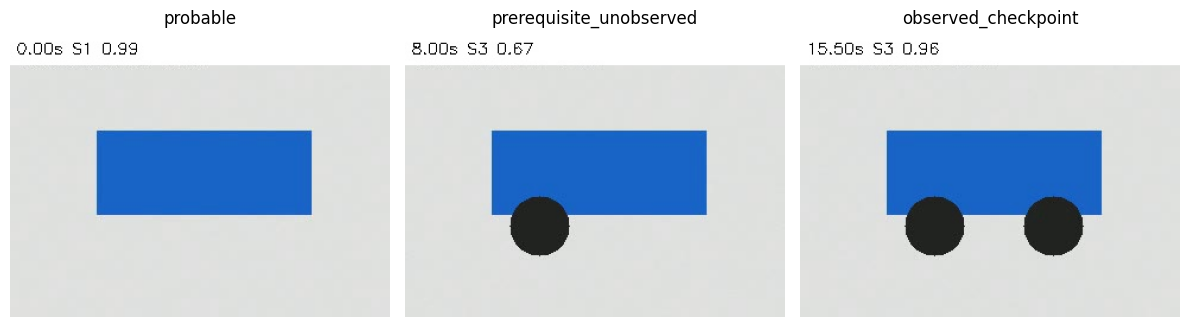

In [6]:
import matplotlib.pyplot as plt
import cv2
rows=report['timeline']
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,index in zip(axes,[0,len(rows)//2,len(rows)-1]):
    r=rows[index]
    image=cv2.imread(str(WORK/'demo_report'/r['image']))
    ax.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB));ax.axis('off')
    ax.set_title(r['state'])
plt.tight_layout();plt.show()
for r in rows:
    print(f"{r['timestamp_seconds']:5.1f}s  {r['step_id']:7s}  {r['state']:26s} {r['component_check']}")

In [7]:
import unittest
suite=unittest.defaultTestLoader.discover(str(ROOT/'tests'),pattern='test_sprint2.py')
result=unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful()
print('Software rule checks passed. This is not field validation.')

Software rule checks passed. This is not field validation.


..........
----------------------------------------------------------------------
Ran 10 tests in 0.002s

OK


In [8]:
RUN_REAL_TRAINING=False
REAL_MANIFEST=ROOT/'my_data'/'manifest.json'
REAL_PROCEDURE=ROOT/'my_data'/'procedure.json'
if RUN_REAL_TRAINING:
    real_procedure=validate_procedure(json.loads(REAL_PROCEDURE.read_text()))
    real_model,real_metrics=train_model(REAL_MANIFEST,real_procedure,WORK/'real_model')
    print(json.dumps(real_metrics,indent=2))
else:
    print('Real training not run; real assembly accuracy NOT MEASURED.')

Real training not run; real assembly accuracy NOT MEASURED.


In [10]:
RUN_REAL_ANALYSIS=False
REAL_VIDEO=ROOT/'my_data'/'new_demo.mp4'
REAL_MODEL=WORK/'real_model'/'step_model.joblib'
COMPONENT_EVIDENCE=None  # or a reviewed evidence JSON path
if RUN_REAL_ANALYSIS:
    real_report=analyse_video(REAL_VIDEO,REAL_MODEL,REAL_PROCEDURE,WORK/'real_report',
                              component_path=COMPONENT_EVIDENCE)
    print('Report:',WORK/'real_report'/'session_report.html')
    print('Suspected alerts:',real_report['alerts'])
else:
    print('Real recording analysis not run.')

Real recording analysis not run.
